# Setup

In [4]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko,
                                                   add_model_name_to_df,
                                                   df_with_ground_truth_as_kind_of_model)

from halcyon.results.plot_from_df import plot_model_plots, plot_per_gene_mse_heatmap, rotate_x_tick_labels, wrap_titles

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Load from MLFlow

ML runs from high and low noise

In [12]:
runs_to_download = []
runs_to_download.extend(
    mlflow.search_runs(filter_string="attributes.status = 'FINISHED' and tags.run_type = 'model_training_and_prediction'",
                        experiment_ids=['7'], output_format='list'))

In [ ]:
runs_to_download.extend(mlflow.search_runs(
    filter_string="attributes.status = 'FINISHED' and tags.run_type = 'model_training_and_prediction' and tags.mlflow.parentRunId = 'f02bf732b2ba4817b254bd5174f1549b'",
      experiment_ids=['6'], output_format='list'))
print(len(runs_to_download))


18


In [14]:
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-04-17 11:49:48,289 - INFO - Downloading artifacts for run cf8f67e98c774367ac795f3649870df0


2026-04-17 11:49:59,225 - INFO - Downloading artifacts for run e7c16d8357fd455698956ee1b9d608e3


2026-04-17 11:50:00,420 - INFO - Downloading artifacts for run 57560dff33bd47e9a5203ca2f718573b


2026-04-17 11:50:01,519 - INFO - Downloading artifacts for run a3e3ebf4de3b47e88853c58a321e8c6a


2026-04-17 11:50:02,644 - INFO - Downloading artifacts for run 9f2457ce38e140518cf35d3c05d4ba03


...

2026-04-17 11:50:25,495 - INFO - Downloading artifacts for run 5922b969bd6942d0bf5e7bf6901952e9


2026-04-17 11:50:26,538 - INFO - Downloading artifacts for run e6f120fab5b24d2ba199a4a7fa78ec25


2026-04-17 11:50:27,742 - INFO - Downloading artifacts for run c24b7e48838c4020830d1f4bd8cd5232


2026-04-17 11:50:30,201 - INFO - Downloading artifacts for run e467ba40a67a4f82be8ea111bb0ff48f


,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.018256,0.018256,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a
1,Node_1,0.0,0.602953,0.602953,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a
2,Node_2,0.0,0.064996,0.064996,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a
3,Node_3,0.0,0.678937,0.678937,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a
4,Node_4,0.0,0.000000,0.000000,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a


In [15]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    run = mlflow.get_run(run_id)
    model_name_records.append({
        'run_id': run_id,
        'model_name': run.data.tags['mlflow.runName'],
        'modelled_genes': run.data.params.get('modelled_gene_labels', None)})
model_name_df = pd.DataFrame(model_name_records)
model_name_df

,run_id,model_name,modelled_genes
0,cf8f67e98c774367ac795f3649870df0,MLP,None
1,e7c16d8357fd455698956ee1b9d608e3,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod..."
2,57560dff33bd47e9a5203ca2f718573b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
3,a3e3ebf4de3b47e88853c58a321e8c6a,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
4,9f2457ce38e140518cf35d3c05d4ba03,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No..."
5,2f3e46c732ee4af6934c5145d996a857,HybridModel,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '..."
6,374a8c6f09fe496f9b92dc2853947e02,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N..."
7,1bd5b2967c6f41739bc6e4211621e93b,HybridModel,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '..."
8,423588fe337243238d5037f32f73bbf0,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No..."
9,1ad11161345e42a09f550f7e061090c3,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."


In [16]:
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')

Add number of genes and noise level

In [17]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    run = mlflow.get_run(run_id)
    records.append({
        'parent_run_id': run_id,
        'nr_genes': run.data.params['nr_genes'],
        'noise_level': run.data.params['noise_level'],

    })
nr_genes_df = pd.DataFrame(records)
nr_genes_df.head()

,parent_run_id,nr_genes,noise_level
0,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
1,d97c3c9ca88a43b597b360151b25d316,50,HIGH
2,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM


Add noiseless expression values

In [18]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)
long_form_simulation = pd.concat(records, ignore_index=True)

2026-04-17 11:52:09,008 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:09,026 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:09,041 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:09,095 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:09,119 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:09,122 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:09,147 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:09,161 - WARNING - Connection p

2026-04-17 11:52:24,521 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:24,545 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:24,603 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:24,613 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:24,634 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:24,659 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:24,723 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:24,728 - WARNING - Connection p

2026-04-17 11:52:31,158 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:31,179 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:31,266 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:31,273 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:31,304 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:31,348 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:31,428 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-17 11:52:31,440 - WARNING - Connection p

In [19]:
nr_genes_df.head()

,parent_run_id,nr_genes,noise_level
0,7e31a31d88f2426cbd3ec72a483bf90a,50,LOW
1,d97c3c9ca88a43b597b360151b25d316,50,HIGH
2,f02bf732b2ba4817b254bd5174f1549b,50,MEDIUM


In [20]:
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes
0,Node_0,0.0,0.018256,0.018256,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None
1,Node_1,0.0,0.602953,0.602953,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None
2,Node_2,0.0,0.064996,0.064996,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None
3,Node_3,0.0,0.678937,0.678937,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None
4,Node_4,0.0,0.000000,0.000000,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,7e31a31d88f2426cbd3ec72a483bf90a,MLP,None


In [21]:
long_form_simulation.head()

,gene,time,ground_truth,condition,run_id
0,Node_0,0.0,0.022225,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a
1,Node_1,0.0,0.557310,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a
2,Node_2,0.0,0.080057,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a
3,Node_3,0.0,0.702816,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a
4,Node_4,0.0,0.057769,KO: Node_0. Env: None,7e31a31d88f2426cbd3ec72a483bf90a


Merging

In [22]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])

outcome = pd.merge(outcome, nr_genes_df, on='parent_run_id')

In [23]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation', 'nr_genes', 'noise_level']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})


outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_genes,noise_level
0,Node_0,0.0,0.018256,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,MLP,None,0.022225,50,LOW
1,Node_1,0.0,0.602953,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,MLP,None,0.557310,50,LOW
2,Node_2,0.0,0.064996,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,MLP,None,0.080057,50,LOW
3,Node_3,0.0,0.678937,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,MLP,None,0.702816,50,LOW
4,Node_4,0.0,0.000000,KO: Node_16. Env: None,cf8f67e98c774367ac795f3649870df0,MLP,None,0.057769,50,LOW
...,...,...,...,...,...,...,...,...,...,...
1889995,Node_45,1.0,1.003480,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.925542,50,MEDIUM
1889996,Node_46,1.0,0.394155,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.321352,50,MEDIUM
1889997,Node_47,1.0,0.190476,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.138196,50,MEDIUM
1889998,Node_48,1.0,0.806056,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.833160,50,MEDIUM


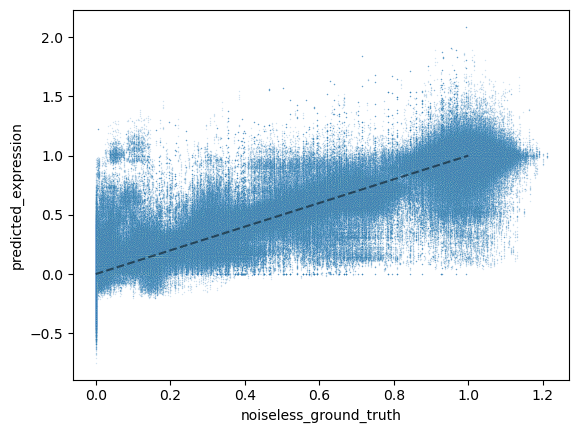

In [26]:
g =sns.scatterplot(data=outcome[outcome['model_name'] == 'HybridModel'], x='noiseless_ground_truth', y='predicted_expression', s=1, alpha=.2)
g.plot([0, 1], [0, 1], 'k--', alpha=0.5)

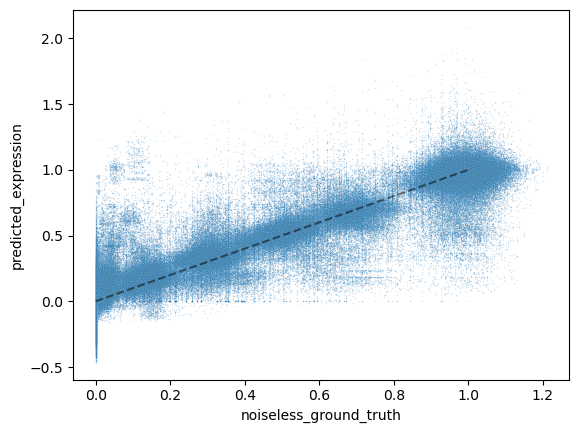

In [25]:
g =sns.scatterplot(data=outcome[outcome['model_name'] == 'MLP'], x='noiseless_ground_truth', y='predicted_expression', s=1, alpha=.2)
g.plot([0, 1], [0, 1], 'k--', alpha=0.5)

In [16]:
import re

def make_ko_lookup(df):
    unique_combos = df[['condition', 'modelled_genes']].drop_duplicates()
    
    lookup = {}
    for _, row in unique_combos.iterrows():
        cond = row['condition']
        genes = row['modelled_genes']
        kos = re.findall(r"Node_\d+", cond)
        
        if genes is None:
            ko_in_modelled_genes = False
        else:
            ko_in_modelled_genes = all(f"'{ko}'" in genes for ko in kos)
        
        key = (cond, genes)
        lookup[key] = ko_in_modelled_genes
    
    return lookup

lookup = make_ko_lookup(outcome)
outcome['ko_in_modelled'] = outcome.apply(
    lambda row: lookup[(
        row['condition'],
        row['modelled_genes'] if row['modelled_genes'] is not None else None
    )],
    axis=1
)
outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_genes,ko_in_modelled
0,Node_0,0.0,0.763922,KO: Node_53. Env: None,5ce0f51a9c8b4ed39a54d85eb4b3b770,HybridModel,"['Node_78', 'Node_22', 'Node_26', 'Node_73', '...",0.825063,100,False
1,Node_1,0.0,0.708528,KO: Node_53. Env: None,5ce0f51a9c8b4ed39a54d85eb4b3b770,HybridModel,"['Node_78', 'Node_22', 'Node_26', 'Node_73', '...",0.666242,100,False
2,Node_2,0.0,0.250820,KO: Node_53. Env: None,5ce0f51a9c8b4ed39a54d85eb4b3b770,HybridModel,"['Node_78', 'Node_22', 'Node_26', 'Node_73', '...",0.291667,100,False
3,Node_3,0.0,0.992782,KO: Node_53. Env: None,5ce0f51a9c8b4ed39a54d85eb4b3b770,HybridModel,"['Node_78', 'Node_22', 'Node_26', 'Node_73', '...",0.830106,100,False
4,Node_4,0.0,1.118541,KO: Node_53. Env: None,5ce0f51a9c8b4ed39a54d85eb4b3b770,HybridModel,"['Node_78', 'Node_22', 'Node_26', 'Node_73', '...",0.940870,100,False
...,...,...,...,...,...,...,...,...,...,...
4544227,Node_44,1.0,0.074938,"KO: Node_1, Node_15. Env: None",d4adee2c979c4452b9e970152af0b3f4,PyTorchODE,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.066099,100,True
4544228,Node_60,1.0,0.520854,"KO: Node_1, Node_15. Env: None",d4adee2c979c4452b9e970152af0b3f4,PyTorchODE,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.482732,100,True
4544229,Node_70,1.0,0.356031,"KO: Node_1, Node_15. Env: None",d4adee2c979c4452b9e970152af0b3f4,PyTorchODE,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.519153,100,True
4544230,Node_82,1.0,0.549414,"KO: Node_1, Node_15. Env: None",d4adee2c979c4452b9e970152af0b3f4,PyTorchODE,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.515219,100,True


In [19]:
outcome[(outcome['condition'] == 'KO: Node_3, Node_7. Env: None') & (outcome['modelled_genes'] == "['Node_31', 'Node_20', 'Node_27', 'Node_34', 'Node_50', 'Node_64', 'Node_75', 'Node_72', 'Node_62']")]

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_genes,ko_in_modelled
2270100,Node_0,0.0,0.697691,"KO: Node_3, Node_7. Env: None",fcad0d813fcd45ddb3d0ccc558385123,HybridModel,"['Node_31', 'Node_20', 'Node_27', 'Node_34', '...",0.596854,100,False
2270101,Node_1,0.0,0.245496,"KO: Node_3, Node_7. Env: None",fcad0d813fcd45ddb3d0ccc558385123,HybridModel,"['Node_31', 'Node_20', 'Node_27', 'Node_34', '...",0.140382,100,False
2270102,Node_2,0.0,0.174458,"KO: Node_3, Node_7. Env: None",fcad0d813fcd45ddb3d0ccc558385123,HybridModel,"['Node_31', 'Node_20', 'Node_27', 'Node_34', '...",0.327658,100,False
2270103,Node_3,0.0,0.625800,"KO: Node_3, Node_7. Env: None",fcad0d813fcd45ddb3d0ccc558385123,HybridModel,"['Node_31', 'Node_20', 'Node_27', 'Node_34', '...",0.653099,100,False
2270104,Node_4,0.0,1.011322,"KO: Node_3, Node_7. Env: None",fcad0d813fcd45ddb3d0ccc558385123,HybridModel,"['Node_31', 'Node_20', 'Node_27', 'Node_34', '...",0.973529,100,False
...,...,...,...,...,...,...,...,...,...,...
2272195,Node_95,1.0,0.540904,"KO: Node_3, Node_7. Env: None",fcad0d813fcd45ddb3d0ccc558385123,HybridModel,"['Node_31', 'Node_20', 'Node_27', 'Node_34', '...",0.604428,100,False
2272196,Node_96,1.0,0.257059,"KO: Node_3, Node_7. Env: None",fcad0d813fcd45ddb3d0ccc558385123,HybridModel,"['Node_31', 'Node_20', 'Node_27', 'Node_34', '...",0.435956,100,False
2272197,Node_97,1.0,0.844792,"KO: Node_3, Node_7. Env: None",fcad0d813fcd45ddb3d0ccc558385123,HybridModel,"['Node_31', 'Node_20', 'Node_27', 'Node_34', '...",1.011262,100,False
2272198,Node_98,1.0,1.039767,"KO: Node_3, Node_7. Env: None",fcad0d813fcd45ddb3d0ccc558385123,HybridModel,"['Node_31', 'Node_20', 'Node_27', 'Node_34', '...",0.895915,100,False


In [27]:
outcome['model_name'].unique()

array(['MLP', 'HybridModel'], dtype=object)

In [28]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

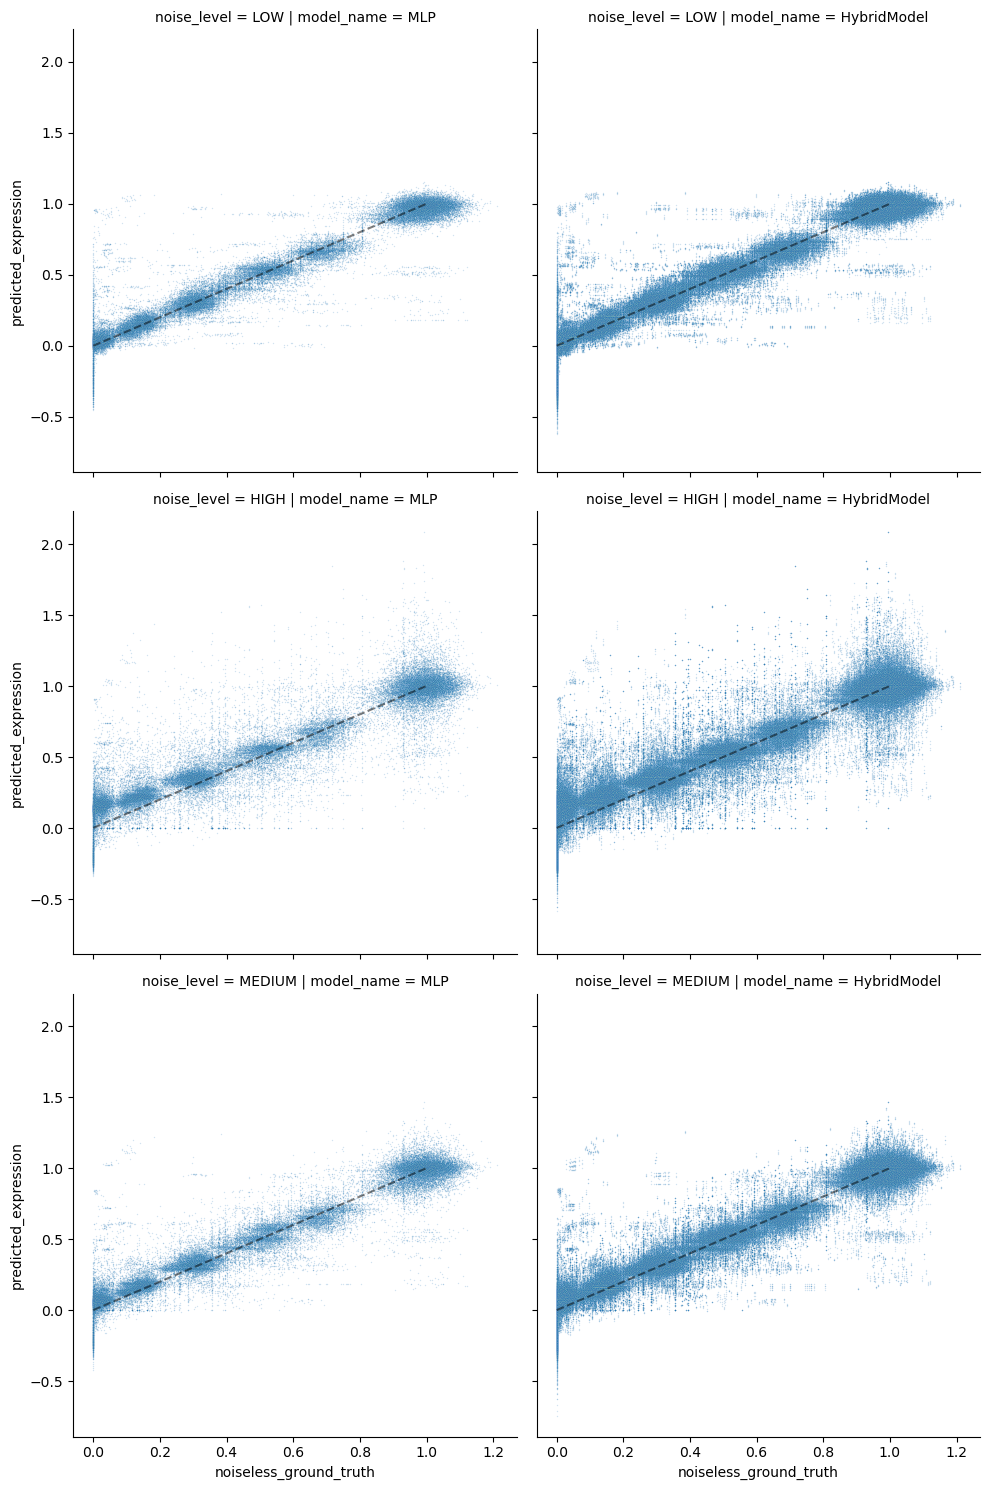

In [30]:
g =sns.relplot(data=single_ko_df[single_ko_df['model_name'].isin(['HybridModel', 'MLP'])], kind='scatter', x='noiseless_ground_truth', y='predicted_expression', col='model_name', row='noise_level', s=1, alpha=.2)

for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)

In [ ]:
double_ko_df['ko_in_modelled'].value_counts()

In [ ]:
double_ko_df.groupby('nr_genes')['condition'].nunique()

In [ ]:
single_ko_df.groupby('nr_genes')['condition'].nunique()

# Plotting

In [31]:
df_with_model_name = double_ko_df.copy()

In [40]:
from matplotlib.colors import LogNorm, Normalize
from sklearn.metrics import mean_squared_error
import scipy.cluster.hierarchy as sch

robust_cmap = True
norm_function = Normalize
cmap = "viridis"

# TODO check for the various hybrid models and how they differ

# If making heatmap remove the KO in modelled groupby. If making boxenplot keep it to be able to split by it.
groupby_list = [
    'model_name',
    # 'ko_in_modelled',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    'noise_level'
]
mse_df = (
    df_with_model_name.groupby(groupby_list)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)


In [36]:
mse_df.sort_values('MSE', ascending=False)

,model_name,gene,condition,noise_level,MSE
13617,MLP,Node_45,"KO: Node_6, Node_23. Env: None",HIGH,1.098567
13629,MLP,Node_45,"KO: Node_7, Node_23. Env: None",HIGH,1.008172
12267,MLP,Node_37,"KO: Node_6, Node_23. Env: None",HIGH,1.001061
13551,MLP,Node_45,"KO: Node_12, Node_23. Env: None",HIGH,0.902620
13563,MLP,Node_45,"KO: Node_2, Node_23. Env: None",HIGH,0.862127
...,...,...,...,...,...
1561,HybridModel,Node_18,"KO: Node_2, Node_17. Env: None",LOW,0.000094
1645,HybridModel,Node_18,"KO: Node_8, Node_16. Env: None",LOW,0.000087
9145,MLP,Node_18,"KO: Node_8, Node_16. Env: None",LOW,0.000079
9061,MLP,Node_18,"KO: Node_2, Node_17. Env: None",LOW,0.000073


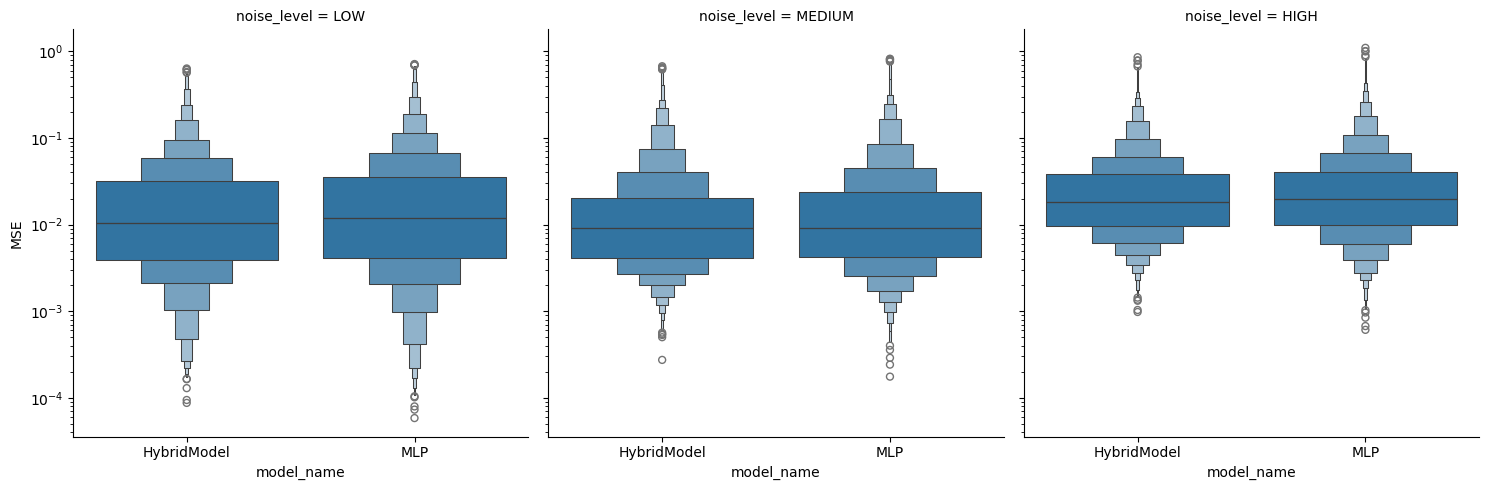

In [43]:
sns.catplot(kind='boxen', col='noise_level', x='model_name', y='MSE', data=mse_df, order=['HybridModel', 'MLP'], col_order=['LOW', 'MEDIUM', 'HIGH'], log_scale=True) # , split=True)

In [44]:
if robust_cmap:
    vmin, vmax = np.percentile(mse_df[DfColumnNames.MSE_COL].dropna(), [1, 99])
    norm = norm_function(vmin=vmin, vmax=vmax)
else:
    norm = norm_function(
        vmin=mse_df[DfColumnNames.MSE_COL].min(),
        vmax=mse_df[DfColumnNames.MSE_COL].max(),
    )

In [45]:
# Use how often gene shows up (i.e. if it is in MM or not) to order rows
gene_order = mse_df.groupby('nr_genes')[DfColumnNames.GENE_COL].value_counts().index.to_list()

from collections import defaultdict

gene_order_dict = defaultdict(list)
for key, node in gene_order:
    gene_order_dict[key].append(node)
    
gene_order_dict

KeyError: 'nr_genes'

In [ ]:
cond_order = mse_df.groupby('nr_genes')[DfColumnNames.CONDITION_COL].value_counts().index.to_list()

cond_order_dict = defaultdict(list)
for key, node in cond_order:
    cond_order_dict[key].append(node)
    
cond_order_dict

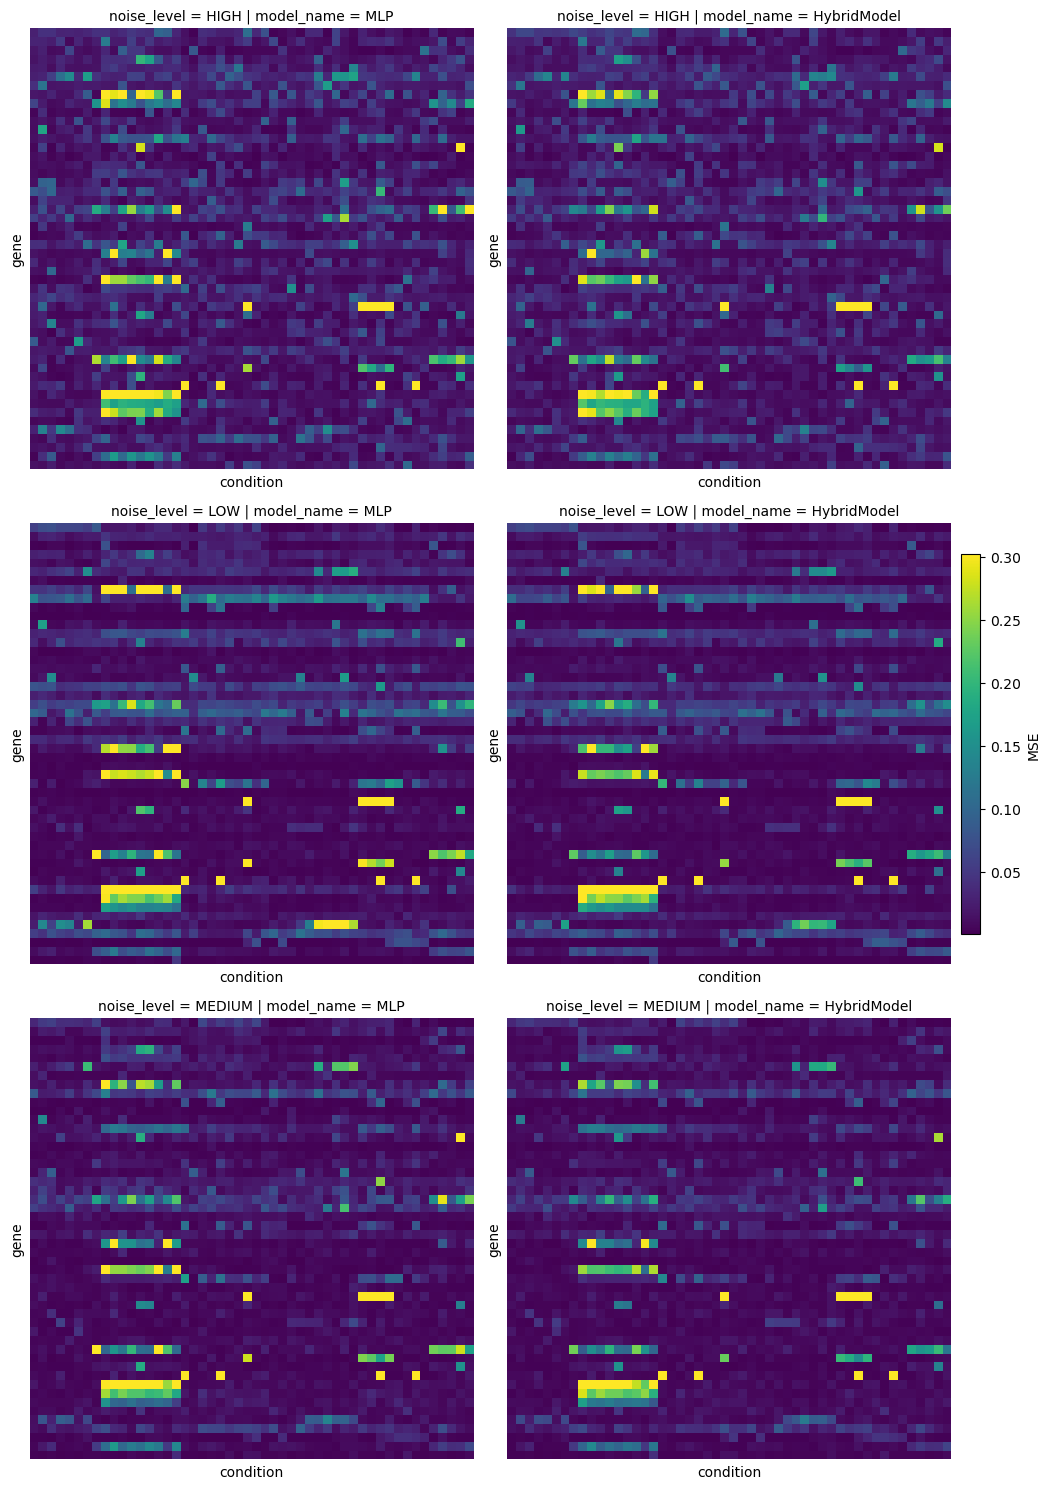

In [47]:

# Do the actual plotting
g = sns.FacetGrid(
    mse_df, col='model_name', row='noise_level', margin_titles=False, aspect=1, height=5, sharex=False, sharey=False, col_order=['MLP', 'HybridModel']# , 'PyTorchODE'],
)

def _plot_heatmap_func(data, **kwargs):
    # nr_genes = data['gene'].nunique()
    # gene_order = gene_order_dict[str(nr_genes)]
    # cond_order = cond_order_dict[str(nr_genes)]
    df_pivot = data.pivot(
        index=DfColumnNames.GENE_COL,
        columns=DfColumnNames.CONDITION_COL,
        values=DfColumnNames.MSE_COL,
    )# .reindex(index=gene_order, columns=cond_order) # , columns=col_order)
    sns.heatmap(data=df_pivot, cmap=cmap, norm=norm, cbar=False, **kwargs)

g.map_dataframe(_plot_heatmap_func)


# Remove all gene and condition names
for ax in g.axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

# add one shared colourbar
mappable = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
mappable.set_array([])
g.figure.tight_layout()
g.figure.colorbar(mappable, ax=g.axes, fraction=0.02, pad=0.01, label="MSE")

In [48]:
for_scatter = mse_df.pivot(index=['gene', 'condition', 'noise_level'], columns='model_name', values='MSE').reset_index()
for_scatter.head()

model_name,gene,condition,noise_level,HybridModel,MLP
0,Node_0,"KO: Node_0, Node_13. Env: None",HIGH,0.042950,0.027386
1,Node_0,"KO: Node_0, Node_13. Env: None",LOW,0.055411,0.057201
2,Node_0,"KO: Node_0, Node_13. Env: None",MEDIUM,0.033153,0.033210
3,Node_0,"KO: Node_0, Node_19. Env: None",HIGH,0.064185,0.042280
4,Node_0,"KO: Node_0, Node_19. Env: None",LOW,0.065455,0.070121


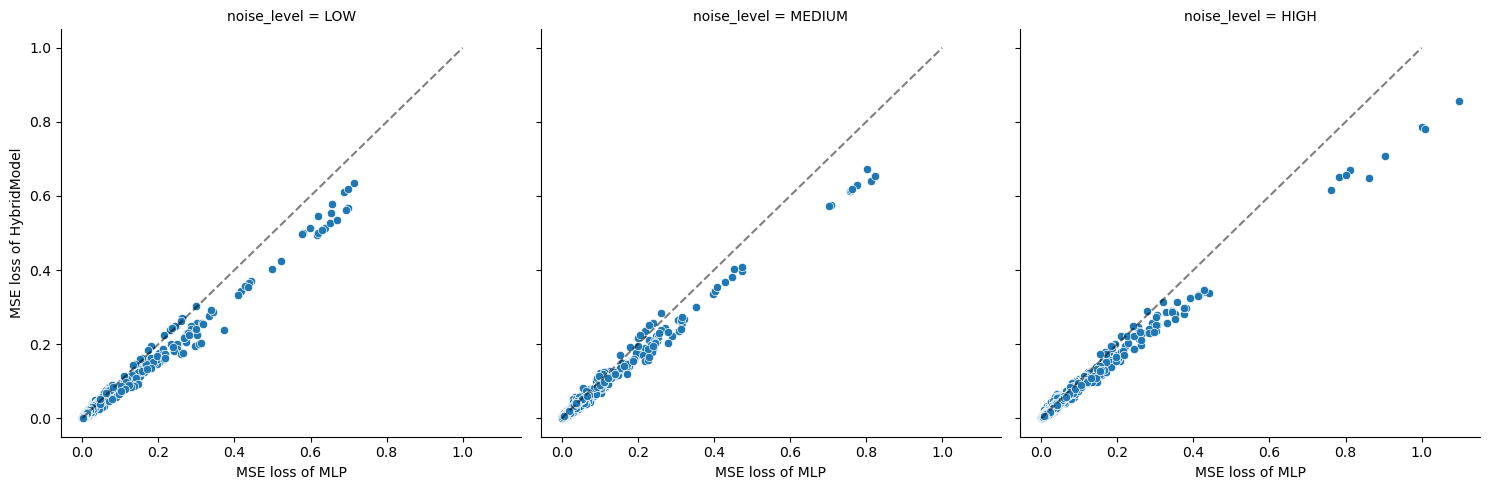

In [50]:
g = sns.relplot(data=for_scatter, x='MLP', y='HybridModel', col='noise_level', col_order=['LOW', 'MEDIUM', 'HIGH'])

for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    ax.set_xlabel('MSE loss of MLP')
    ax.set_ylabel('MSE loss of HybridModel')